# Bedroom Humidity Forecasting


***

#### Notebook Overview


#### Data Overview

***
#### Key Findings

#### Next Steps

## Imports

In [3]:
# preprocessing
from utils import DataCleanPipleLine

# funcs
from utils.useful_funcs import season_decomp, model_vs_reality
from utils.ml_pipeline import *
# viz
import matplotlib.pyplot as plt
import seaborn as sns
from utils import plotting as plot

# files
import os

# time series eda
from statsmodels.tsa.seasonal import STL

# ACF / PACF (numeric values and plots)
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Stationarity tests
from statsmodels.tsa.stattools import adfuller, kpss

# models

# ARIMA / SARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX   # SARIMA = SARIMAX without exog

# Gradient boosting
#from xgboost import XGBRegressor

# Random forest and linear regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

## Data Import

In [4]:

# import data
file_location = os.getenv("F_LOC")

# run data load
cleaning_pipeline = DataCleanPipleLine
pipe_obj = cleaning_pipeline.DataImportAndCleaningPipeline(file_location)

# run pipeline
window_df = pipe_obj.RunPipeline(impute_missing_data=True)



****************************************************************************************************
DF Shape: (266697, 4)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure   Humidity
266696  2026-11-24 11:44:38             14.46  1001.00030  55.114256
266697  2026-11-24 11:45:38             14.47  1000.92800  54.859376
266698  2026-11-24 11:46:38             14.48  1001.03064  54.136720
266699  2026-11-24 11:47:38             14.46  1000.97370  54.858400
266700  2026-11-24 11:48:39             14.46  1001.01930  54.446290
266701  2026-11-24 11:49:39             14.49  1001.07230  54.671876
266702  2026-11-24 11:50:39             14.46  1000.93950  54.479492
266703  2026-11-24 11:51:39             14.42  1000.93210  55.610350
266704  2026-11-24 11:52:39             14.21  1000.97

## Splitting the data

In [5]:
data_split_dict = train_val_test_split(window_df)

# extract from dict
x_train, x_val, x_test = (
    data_split_dict["x_train"],
    data_split_dict["x_val"],
    data_split_dict["x_test"]
    )

# now targets
y_train, y_val, y_test = (
    data_split_dict["y_train"],
    data_split_dict["y_val"],
    data_split_dict["y_test"]
    )

# get df for eda
train_df = data_split_dict["train_df"]
train_df.head(10)

,Temperature (oC),Pressure,Humidity,DateTime,Sensor_Status,Date,YearMonth,EndOfWeek,Time,Time_Numeric,DailyAvgTemperature,DailyAvgHumidity
2026-03-29 20:54:00+00:00,17.71,999.83000,55.912110,2026-03-29 20:54:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:55:00+00:00,17.68,999.99860,56.043944,2026-03-29 20:55:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:56:00+00:00,17.61,999.81280,55.877930,2026-03-29 20:56:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:57:00+00:00,17.60,999.98488,55.956056,2026-03-29 20:57:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:58:00+00:00,17.61,999.97320,55.732420,2026-03-29 20:58:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:59:00+00:00,17.53,999.97870,55.779296,2026-03-29 20:59:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:00:00+00:00,17.57,1000.03144,55.513670,2026-03-29 21:00:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:01:00+00:00,17.51,1000.08210,55.732420,2026-03-29 21:01:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:02:00+00:00,17.49,1000.09790,55.806640,2026-03-29 21:02:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:03:00+00:00,17.47,1000.14030,55.972656,2026-03-29 21:03:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102


## Time Series Forecasting: Pre-Modelling Analysis

* Distributions
* Trend and seasonality
* Stationarity
* Autocorrelation

In [6]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 220838 entries, 2026-03-29 20:54:00+00:00 to 2026-08-30 05:31:00+00:00
Freq: T
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     220838 non-null  float64            
 1   Pressure             220838 non-null  float64            
 2   Humidity             220838 non-null  float64            
 3   DateTime             183602 non-null  datetime64[ns, UTC]
 4   Sensor_Status        220838 non-null  object             
 5   Date                 220838 non-null  datetime64[ns]     
 6   YearMonth            220838 non-null  period[M]          
 7   EndOfWeek            220838 non-null  datetime64[ns]     
 8   Time                 220838 non-null  object             
 9   Time_Numeric         220838 non-null  timedelta64[ns]    
 10  DailyAvgTemperature  220838 non-null  float64            
 11  DailyAvgHum

### Trend & Seasonality


#### Season Decomposition

1. **Season Decomposition** will be used to understand the overall pattern in Humidity and Temperature. I have chosen this method because of its simplicity for breaking down time-series data into 3 components - Trend, Seasonal & Residual.
* Trend - This is simply the rolling average specified by the user.
* Seasonal - Visualises the trend of the data by using subtracting Trend actual observations, then the mean, such as minutely, hourly daily, is then taken from this.
* A prediction can be created by adding Trend & Seasonal together, which is then compared against actual observations to extract residuals. I can then use the residuals to analyse how well the model performed in generalising the data.

Humidity R2: 0.88


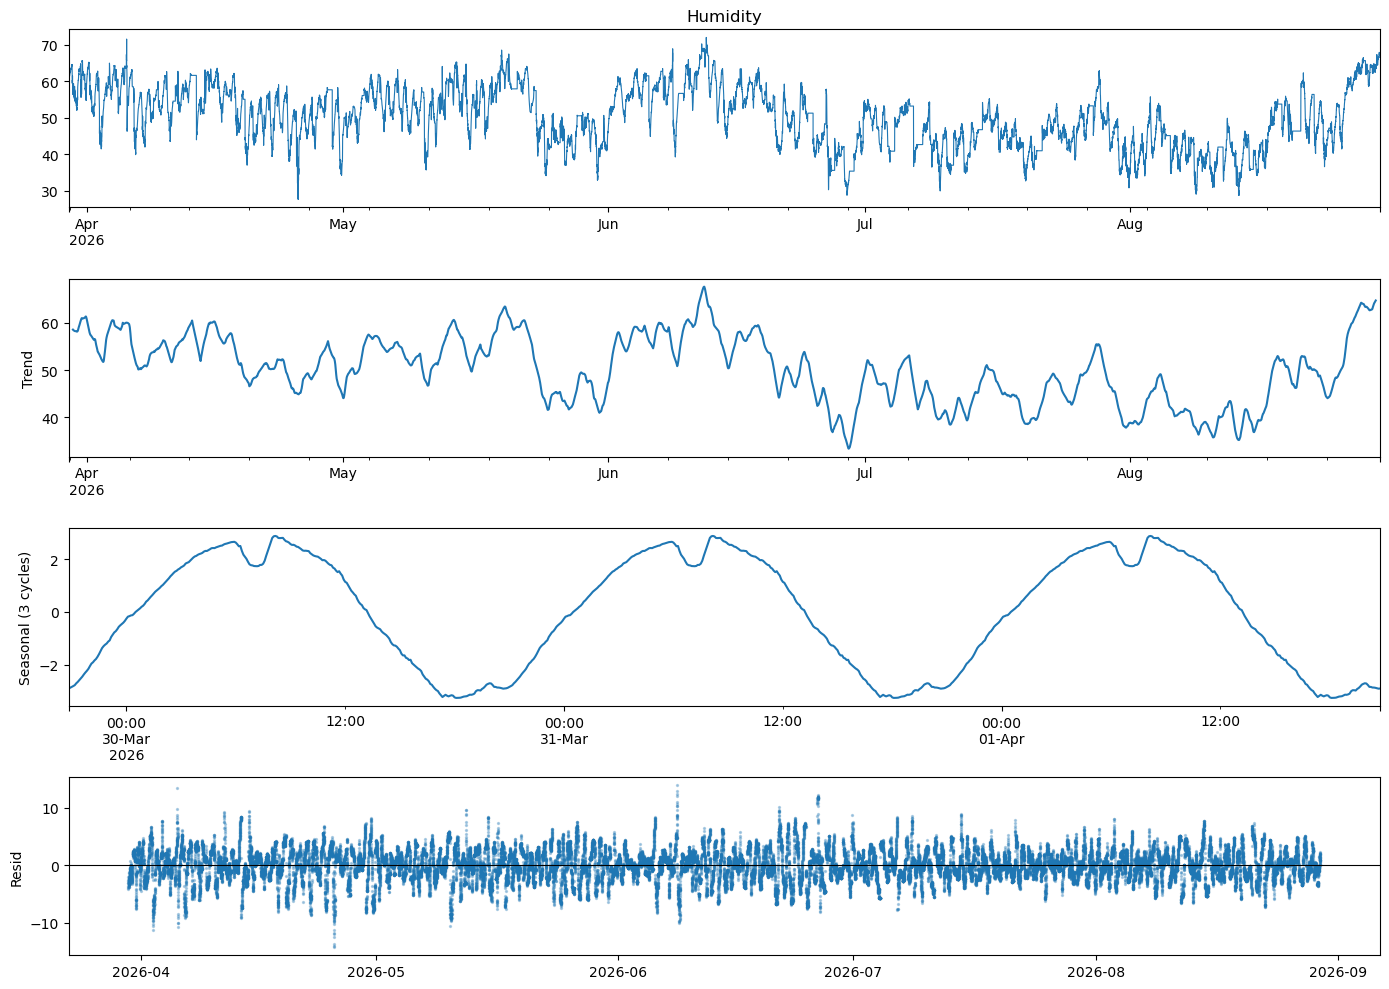

In [7]:
# run seasonal decomposition
feature = ['Humidity']
hum_result = season_decomp(df=train_df[feature],resample_size="5min")


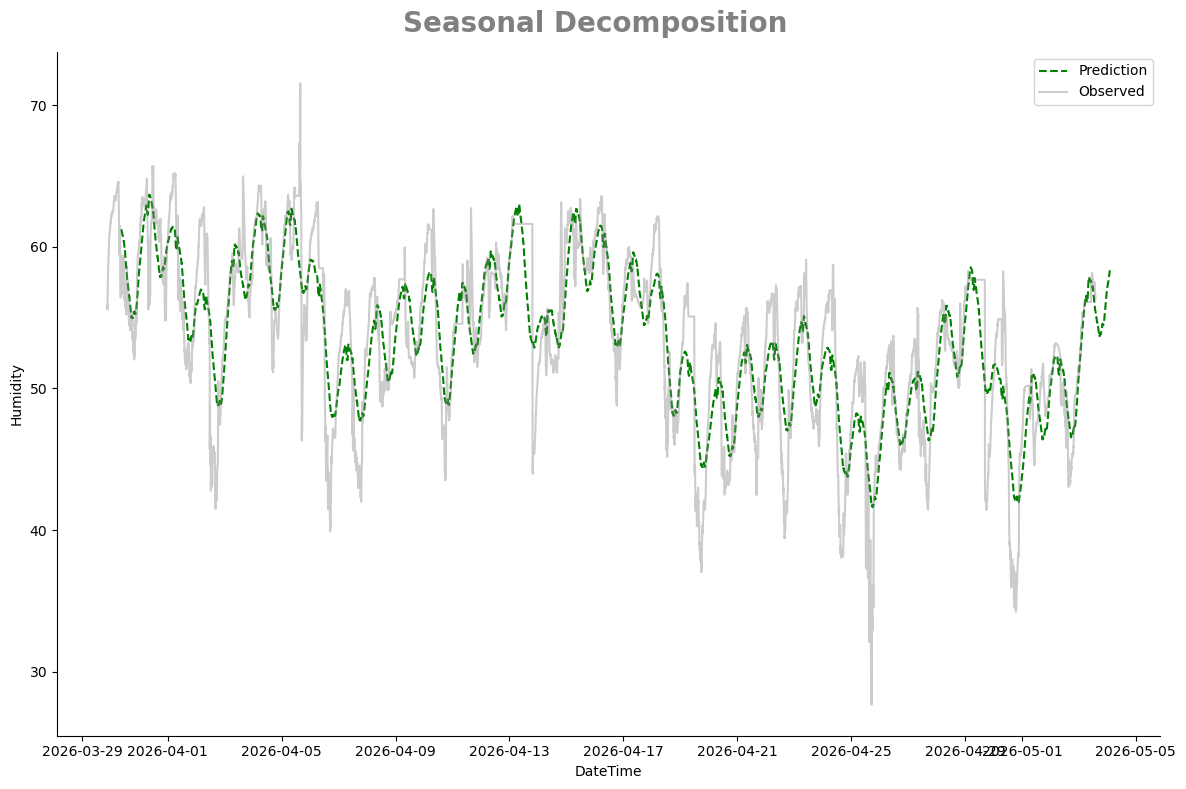

In [8]:
# lets see how the model is against reality
model_vs_reality(model=hum_result, target='Humidity', sample_size=10000)

##### Notes - Humidity Seasonal Decomposition Forecast

1. The model has captured the cycle quite well in that the overall shape of the predicted time series matches to that of the observed. This means that by averaging the difference between trend and observed, the model has captured the daily cycles.
2. However, the model is let down where there are humidity spikes as the predicted lines are +/-10% off the actual - This is the limitation of using mean values as it is being shrunk by the smaller residuals as larger ones appear to be rare.

Temperature (oC) R2: 0.98


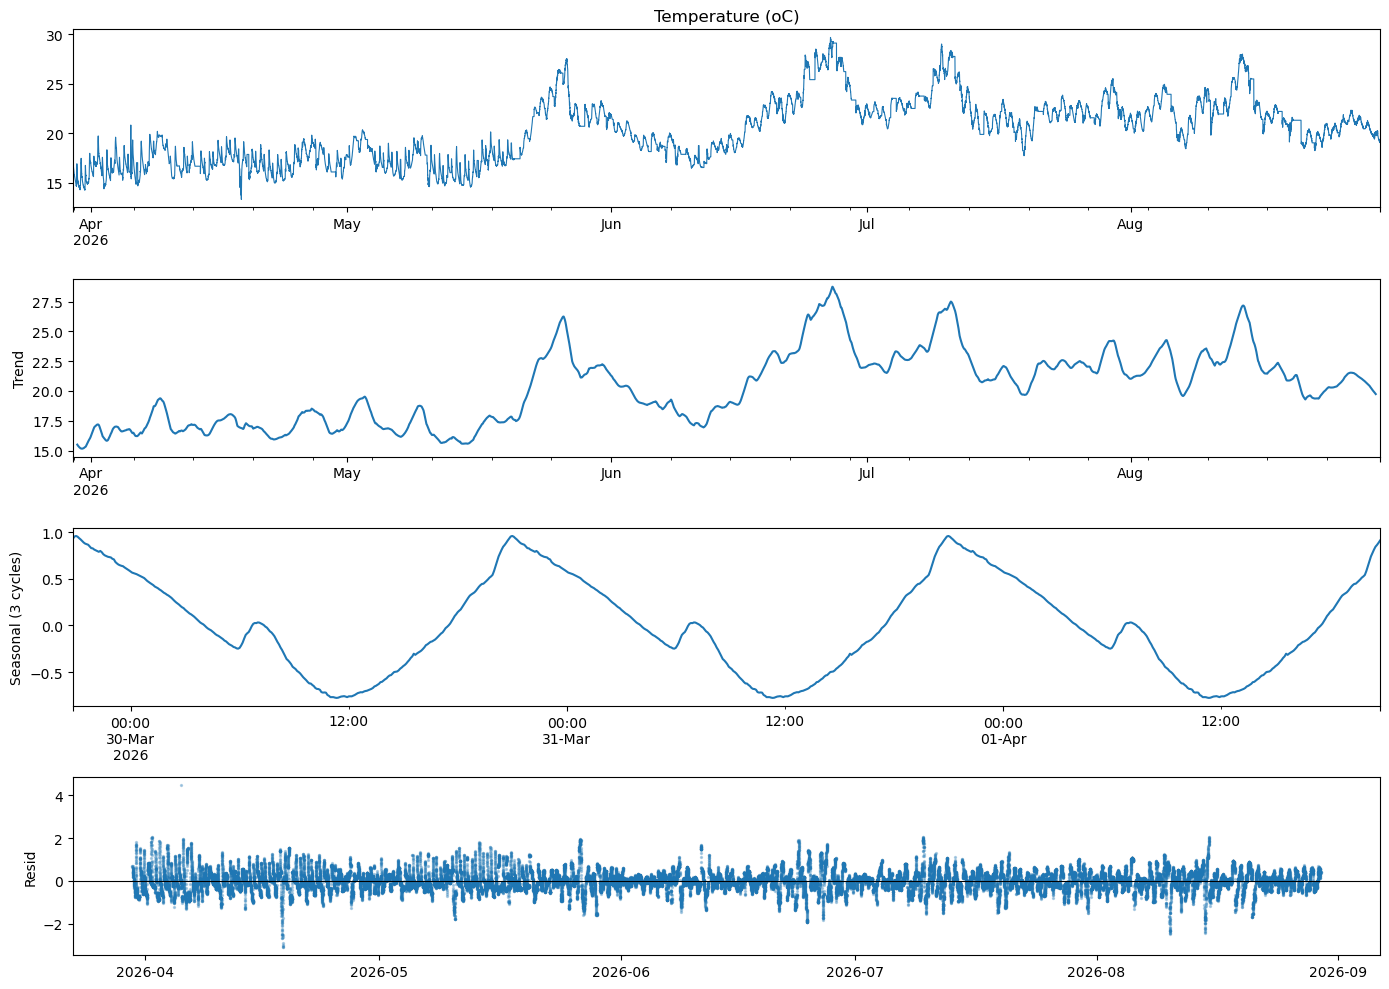

In [9]:
# run seasonal decomposition
feature = ['Temperature (oC)']
tmp_result = season_decomp(df=train_df[feature],resample_size="5min")

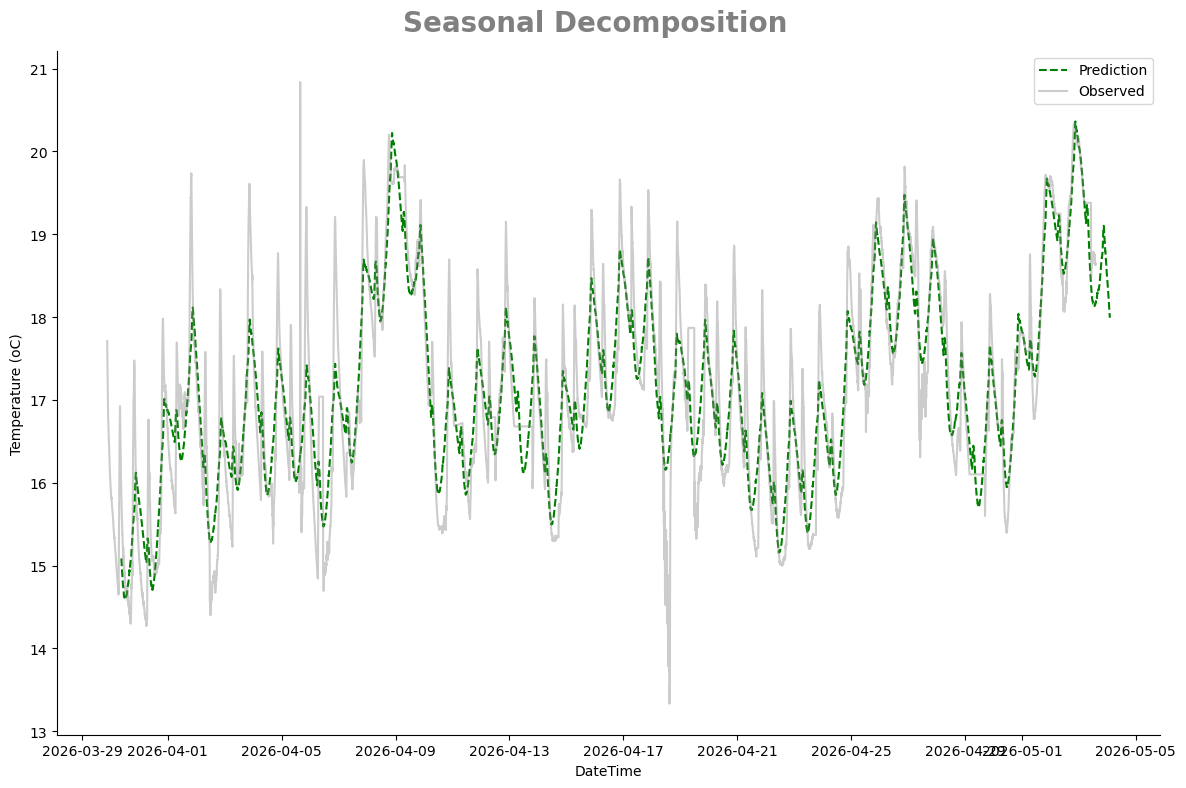

In [10]:
model_vs_reality(model=tmp_result, target='Temperature (oC)', sample_size=10000)

##### Notes - Seasonal Decomposition

1. The seasonal cycles follow a similar pattern as to what I identified in the previous notebook by calculating the hourly median - Humidity peaks early in the morning then the trough is around midday. If I was to reduce condensation in the room, the above and the previous notebook suggests that a dehumidifier should be on early in the morning around 6/7am.
2. The Residual plots show random spikes where the output of the model, potentially identifying where humidity almost breaks predictibility - this could be the imputed data.
3. The residuals over time appear to follow a wave pattern in both positive and negative regions, which means in some days it does ok to predict humidity, while others it was poor. This suggests the Humidity levels on its own breaks a cycle which the model fails to capture well.
4. The trend plot shows a slow declinging humidity levels over time, further supporting my claim of hotter months equates to less humidity.
5. The plot has also identified seasonality, which is unsurpising as this is atmospheric data.

### STL

In [11]:

minutely = "5min"
period = int(pd.Timedelta("1D") / pd.Timedelta(minutely))
# resample the data
minutely_mean = train_df[['Humidity']].resample(minutely).mean()

# fit to data
stl = STL(minutely_mean, period=period)
res = stl.fit()


# plot results
fig, axes = plt.subplots(5, 1, figsize=(14, 10))
res.observed.plot(ax=axes[0], lw=0.6, title="Humidity")
res.trend.plot(ax=axes[1], ylabel="Trend")
res.seasonal.plot(ax=axes[2], ylabel="Seasonal")
res.seasonal.iloc[:period * 10].plot(ax=axes[3], ylabel="Seasonal (10 Days)")
axes[4].scatter(res.resid.index, res.resid.values, s=1, alpha=0.2, rasterized=True)
axes[4].axhline(0, color="black", lw=0.8)
axes[4].set_ylabel("Resid")
plt.tight_layout()

ValueError: endog must have ndim <= 1

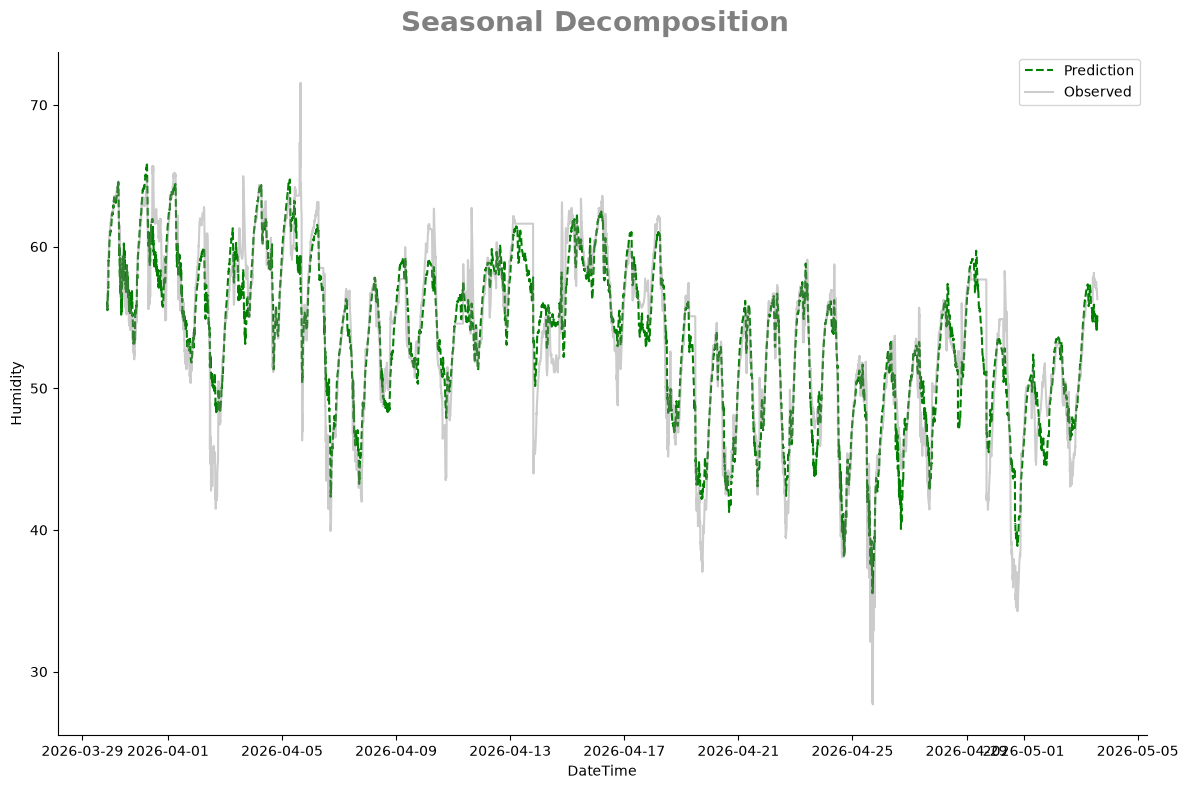

In [ ]:
#review predictions!
model_vs_reality(model=res, target='Humidity', sample_size=10000)


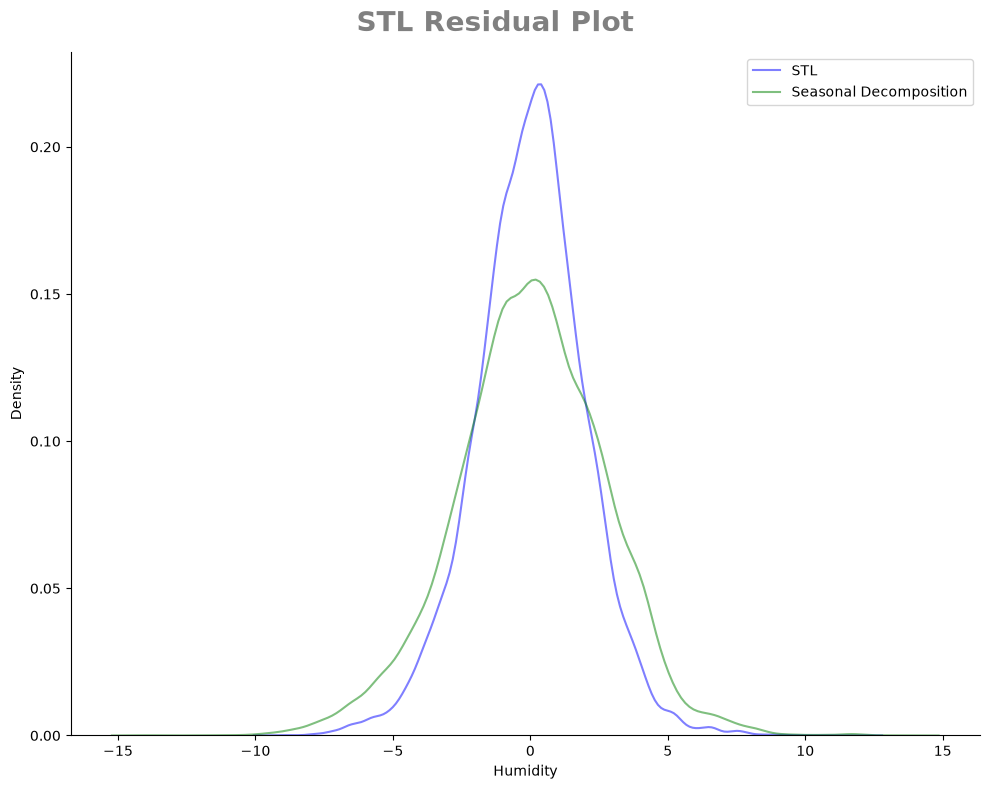

In [ ]:
# lets create a residual plot to see how the errors are distributed
# and compare to our seasonal decomp
stl_residuals = res.resid
sd_residuals = hum_result.resid
fig = plt.figure(figsize=(10,8))

for idx,residual in enumerate([stl_residuals,sd_residuals]):
    sns.kdeplot(
        residual,
        label='STL' if idx == 0 else 'Seasonal Decomposition',
        color='blue' if idx == 0 else 'green',
        alpha=0.5
        )

plt.legend()
# clean the plot
plot.plot_cleanup(None,"STL Residual Plot",xlabel="Humidity")

##### Notes

We can see that the STL predictions are significantly closer to the observed values due to the residual distribution being closer to 0 - The plot shows a thinner and taller STL residual distribution compared to Seasonal Decomposition. This is significant in terms of EDA and decomposing the cyclic behaviour because the seasonality of STL better captures the daily cycles of humidity across the training set compared to Seasonal Decomposition, which means the seasonal results observed in the STL model are more reliable than those from the other method. 

The decomposition of the data shows the following:
1. The cycle heights are not constant as the heights vary depending on the month. This, arguably, reflects real-world temperature patterns as humidity levels do not cycle to and from the same value as other variables play a role, such as temperature.
2. April and May Seasonality shows large height in cyclic waves in comparison to warmer months such as June and July. This could imply the visual representation of warmer months has on the behaviour of humidity - It would be interesting to see if Oct, November and December are similar (or worse) to April and May.
3. The residuals of STL show a similar range over time +/- 10, where there are random spikes over time. Perhaps this is evidence of my imputed data not being sufficient?




##### How is STL better at this?

Classical decomposition estimates the trend with a moving average and gives each season a single fixed average, so it struggles when the seasonal pattern changes over time and when outliers are present (more or less a naive approach). STL replaces those averages with local regression - this simply means the method takes subsamples over time (that adheres to time-series data properties) and fits a line (low-degree polynomial) in these subsamples using weighted least squares. 

Each observation's weight depends on its distance from the point being estimated (The further the observation, the lesser the weight), falling smoothly from 1 at the centre to 0 at the edge of the window. Because each squared residual is multiplied by its weight, nearby points dominate the fit and distant points barely register. Only the fitted value at the centre of the window is kept. Repeating this at every point traces out the smooth curve, so no single global polynomial is ever fitted.

Therefore, the STL is a more reliable tool because:
1. It accounts for change in the data over time - The visual above shows how the cycles started tall in height in April and May then decreased in size when it got to warmer months.
2. There is an option to better handle outliers, meaning the model forces outliers to have less pull with the fitted line.


### Modelling

* Naive and seasonal naive baselines
* Classical statistical model (ARIMA / SARIMA)
* Machine learning models (lag and rolling features)
* Model comparison and evaluation

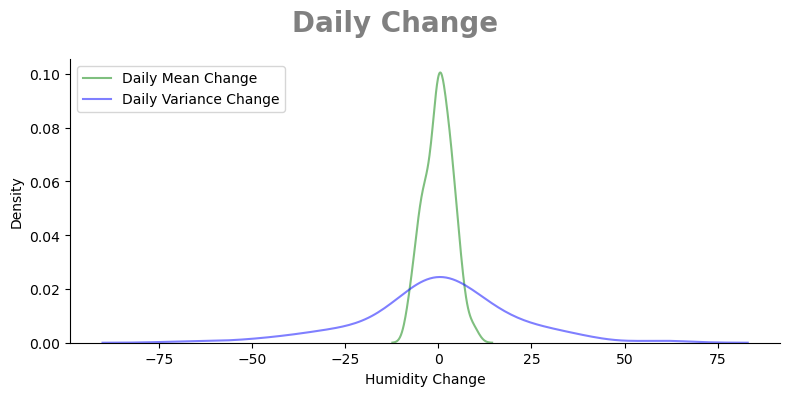

In [57]:
# First I need to test the data for Stationarity, then use ACF & PACF to determine
# the lag terms for ARIMA and SARIMAX

# lets do a quick analysis of the time series stats by day
agged_df = (
    train_df
    .groupby([train_df.index.date])['Humidity']
    .describe()
    )

e = agged_df.assign(
    var = agged_df['std']**2,
    day_mean_lag=(agged_df['mean']-agged_df['mean'].shift(1)).dropna(),
    day_var_lag=(e['var']-e['var'].shift(1)).dropna()
).drop(columns=['count','std','min','25%','50%','75%','max'])

fig = plt.figure(figsize=(8,4));

# visualise the change over day - I expect this to change over time
sns.kdeplot(
    data=e,
    x='day_mean_lag',
    label='Daily Mean Change',
    color='green',
    alpha=0.5
);
sns.kdeplot(
    data=e,
    x='day_var_lag',
    label='Daily Variance Change',
    color='blue',
    alpha=0.5
);

# plot cleanup
plot.plot_cleanup(None,"Daily Change",xlabel="Humidity Change")

plt.legend(loc='upper left');


In [ ]:

# H0: The data is non-stationary
# H1: The data is stationary
minutely_hum = train_df[['Humidity']].copy()


# set up the test
alpha = 0.05 # 95% confidence

result_adf = adfuller(minutely_hum.values)
p = result_adf[1]

# show results
print(f"P-Value {p:.4f}")
if p <= alpha:
    print("Reject the Null Hypothesis. There is evidence that the sample is Stationary")
else:
    print("Unable to reject the Null Hypothesis as there is little evidence to do so.")


P-Value 0.0000
Reject the Null Hypothesis. There is evidence that the sample is Stationary


### Results